# Pick & Place: Qwen3.5-2B → Panda joint keyframes (SFT)

Fine-tunes Qwen3.5-2B (LoRA) to read the **top + wrist RGB images**, the task, the phase and the current joints,
and output the **next joint keyframe**:

```
j: 12.4 18.7 -3.1 -121.6 2.0 140.3 54.8 | gripper: open
```

Data comes from `generate_dataset.py` (expert IK labels, 8 phases per episode). Based on the Unsloth Qwen3.5 (2B) Vision notebook.

**Run order:** Install → Config → Model → LoRA → Data → Train → Save → Evaluate.

In [1]:
!pip show torch 

Name: torch
Version: 2.6.0+cu124
Summary: Tensors and Dynamic neural networks in Python with strong GPU acceleration
Home-page: https://pytorch.org/
Author: PyTorch Team
Author-email: packages@pytorch.org
License: BSD-3-Clause
Location: /home/asus/.local/lib/python3.10/site-packages
Requires: filelock, fsspec, jinja2, networkx, nvidia-cublas-cu12, nvidia-cuda-cupti-cu12, nvidia-cuda-nvrtc-cu12, nvidia-cuda-runtime-cu12, nvidia-cudnn-cu12, nvidia-cufft-cu12, nvidia-curand-cu12, nvidia-cusolver-cu12, nvidia-cusparse-cu12, nvidia-cusparselt-cu12, nvidia-nccl-cu12, nvidia-nvjitlink-cu12, nvidia-nvtx-cu12, sympy, triton, typing-extensions
Required-by: torchaudio, torchvision, ultralytics, ultralytics-thop


In [2]:
!nvidia-smi

Wed Oct 21 13:27:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 560.35.05              Driver Version: 560.35.05      CUDA Version: 12.6     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4060 ...    Off |   00000000:01:00.0  On |                  N/A |
| N/A   51C    P8              8W /   80W |     521MiB /   8188MiB |     16%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Installation

In [ ]:
%%capture
import os, importlib.util
!pip install --upgrade -qqq uv
if importlib.util.find_spec("torch") is None or "COLAB_" in "".join(os.environ.keys()):
    try: import numpy, PIL; _numpy = f"numpy=={numpy.__version__}"; _pil = f"pillow=={PIL.__version__}"
    except: _numpy = "numpy"; _pil = "pillow"
    !uv pip install -qqq \
        "torch==2.8.0" "triton>=3.3.0" {_numpy} {_pil} torchvision "torchaudio==2.8.0" bitsandbytes xformers==0.0.32.post2 \
        "unsloth_zoo[base] @ git+https://github.com/unslothai/unsloth-zoo" \
        "unsloth[base] @ git+https://github.com/unslothai/unsloth"
    !uv pip install -qqq --no-deps "torchcodec==0.7.0"
elif importlib.util.find_spec("unsloth") is None:
    !uv pip install -qqq unsloth
!uv pip install --upgrade --no-deps "tokenizers>=0.22.0,<=0.23.0" trl==0.22.2 unsloth unsloth_zoo
!uv pip install transformers==5.2.0
!unsloth install-kernels
!uv pip install --no-deps --upgrade "torchao>=0.16.0"

# mujoco is only needed for the gripper-position (FK) metric in eval_pick_place.py
if importlib.util.find_spec("mujoco") is None:
    !uv pip install -qqq mujoco


### Config
Paths are relative to this notebook (`vlm_training/`). On **Colab**, upload a zip with `vlm_training/`, `expert.py`,
`mujoco_pick_place/` and the dataset folder, unzip it, and point `PROJECT_DIR` at it.

In [5]:
import os, sys

PROJECT_DIR  = os.path.abspath("..")            # Colab: e.g. "/content/60_pick_place_advanced"
DATASET_DIR  = os.path.join(PROJECT_DIR, "datasets/pick_place_v1_21-10-2026-11-03-15")
LORA_DIR     = os.path.join(PROJECT_DIR, "checkpoints/qwen35_2b_pickplace_lora")
MODEL_NAME   = "unsloth/Qwen3.5-2B"
LOAD_IN_4BIT = False   # True if you run out of GPU memory (8 GB laptop GPU) - slightly less precise
CAMS         = None    # None = all saved cameras (top + wrist); ["top"] to train on one view

sys.path.insert(0, os.path.join(PROJECT_DIR, "vlm_training"))
assert os.path.exists(os.path.join(DATASET_DIR, "train.jsonl")), f"dataset not found: {DATASET_DIR}"

### Model

In [6]:
from unsloth import FastVisionModel
import torch

model, tokenizer = FastVisionModel.from_pretrained(
    MODEL_NAME,
    load_in_4bit = LOAD_IN_4BIT,
    use_gradient_checkpointing = "unsloth", # saves memory with 2 images per sample
)

==((====))==  Unsloth 2026.10.7: Fast Qwen3_5 patching. Transformers: 5.17.0.
   \\   /|    NVIDIA GeForce RTX 4060 Laptop GPU. Num GPUs = 1. Max memory: 7.644 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.8.0+cu126. CUDA: 8.9. CUDA Toolkit: 12.6. Triton: 3.4.0
\        /    Bfloat16 = TRUE. FA [Xformers = 0.0.32.post2. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: QLoRA and full finetuning all not selected. Switching to 16bit LoRA.


Loading weights:   0%|          | 0/617 [00:00<?, ?it/s]

Unsloth: compiling each transformer block as one region (Qwen3_5DecoderLayer).


### LoRA
Vision layers are fine-tuned too: reading exact cube position and rotation from the image is the hard part of this task.

In [7]:
model = FastVisionModel.get_peft_model(
    model,
    finetune_vision_layers     = True,
    finetune_language_layers   = True,
    finetune_attention_modules = True,
    finetune_mlp_modules       = True,

    r = 16,
    lora_alpha = 16,
    lora_dropout = 0,
    bias = "none",
    random_state = 3407,
    use_rslora = False,
    loftq_config = None,
)

<a name="Data"></a>
### Data
`PickPlaceConversations` returns samples already in the Unsloth chat format and opens images lazily,
so the ~48k JPEGs never sit in RAM at once.

In [8]:
import importlib, pick_place_dataset
importlib.reload(pick_place_dataset)          # picks up the fix without restarting the kernel
from pick_place_dataset import PickPlaceConversations

train_dataset = PickPlaceConversations(DATASET_DIR, split = "train", cams = CAMS).to_hf_dataset()
val_dataset   = PickPlaceConversations(DATASET_DIR, split = "val",   cams = CAMS)
print(f"train {len(train_dataset)}  val {len(val_dataset)}")


train 22616  val 1384


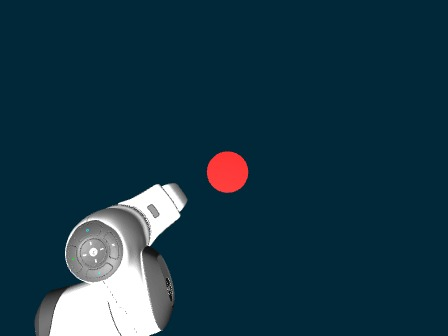

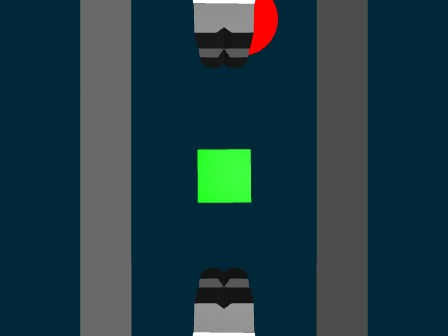

Task: Pick up the green cube and place it on the red pad.
Phase 2/8: GRASP
Current joints (deg): 10.9 5.7 7.7 -141.9 -1.4 147.8 29.3
Current gripper: open
Output the target joint angles j1..j7 in degrees and the gripper command.

LABEL: j: 12.7 24.8 5.5 -140.0 -8.7 164.6 35.1 | gripper: open


In [9]:
from IPython.display import display

sample = val_dataset[1]
for part in sample["messages"][0]["content"]:
    if part["type"] == "image": display(part["image"])
    else: print(part["text"])
print("\nLABEL:", sample["messages"][1]["content"][0]["text"])

Before training, the base model doesn't know the answer format or the robot. This is the baseline.
Decoding is **greedy**: the original notebook's `temperature = 1.5` would make the joint numbers random.

In [10]:
from eval_pick_place import predict

FastVisionModel.for_inference(model)
row = val_dataset.rows[1]
print("label     :", row["answer"])
print("prediction:", predict(model, tokenizer, val_dataset.images(row), row["prompt"]))

label     : j: 12.7 24.8 5.5 -140.0 -8.7 164.6 35.1 | gripper: open


`causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
`causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


prediction: Based on the provided images and the task description, here is the analysis for the current phase:

- **Current State:** The robot's gripper is currently in an open position, as indicated by the "Current gripper: open" text.
- **Target State:** The goal is to grasp the green cube


<a name="Train"></a>
### Train
One epoch ≈ 22.6k samples / (2 × 4) ≈ 2.8k steps. Checkpoints are written every 500 steps, so an interrupted
run can continue with `trainer.train(resume_from_checkpoint = True)`.

In [11]:
from unsloth.trainer import UnslothVisionDataCollator
from trl import SFTTrainer, SFTConfig

FastVisionModel.for_training(model)

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    data_collator = UnslothVisionDataCollator(model, tokenizer), # Must use!
    train_dataset = train_dataset,
    args = SFTConfig(
        per_device_train_batch_size = 2,
        gradient_accumulation_steps = 4,
        warmup_steps = 50,
        num_train_epochs = 1,
        max_steps = 30,          # uncomment for a quick smoke test first
        learning_rate = 2e-4,
        logging_steps = 10,
        save_steps = 500,
        save_total_limit = 2,
        optim = "adamw_8bit",
        weight_decay = 0.001,
        lr_scheduler_type = "linear",
        seed = 3407,
        output_dir = os.path.join(PROJECT_DIR, "checkpoints/outputs"),
        report_to = "none",

        # You MUST put the below items for vision finetuning:
        remove_unused_columns = False,
        dataset_text_field = "",
        dataset_kwargs = {"skip_prepare_dataset": True},
        max_length = 2048,
    ),
)

Unsloth: Model does not have a default image size - using 512


In [12]:
# @title Show current memory stats
gpu_stats = torch.cuda.get_device_properties(0)
start_gpu_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
max_memory = round(gpu_stats.total_memory / 1024 / 1024 / 1024, 3)
print(f"GPU = {gpu_stats.name}. Max memory = {max_memory} GB.")
print(f"{start_gpu_memory} GB of memory reserved.")

GPU = NVIDIA GeForce RTX 4060 Laptop GPU. Max memory = 7.644 GB.
4.338 GB of memory reserved.


In [ ]:
trainer_stats = trainer.train()
# trainer_stats = trainer.train(resume_from_checkpoint = True)   # continue an interrupted run

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 248046}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 22,616 | Num Epochs = 1 | Total steps = 30
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 23,110,656 of 2,236,352,320 (1.03% trained)


Unsloth: Will smartly offload gradients to save VRAM!


In [ ]:
# @title Show final memory and time stats
used_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
used_memory_for_lora = round(used_memory - start_gpu_memory, 3)
used_percentage = round(used_memory / max_memory * 100, 3)
lora_percentage = round(used_memory_for_lora / max_memory * 100, 3)
print(f"{trainer_stats.metrics['train_runtime']} seconds used for training.")
print(
    f"{round(trainer_stats.metrics['train_runtime']/60, 2)} minutes used for training."
)
print(f"Peak reserved memory = {used_memory} GB.")
print(f"Peak reserved memory for training = {used_memory_for_lora} GB.")
print(f"Peak reserved memory % of max memory = {used_percentage} %.")
print(f"Peak reserved memory for training % of max memory = {lora_percentage} %.")

<a name="Save"></a>
### Save LoRA adapters

In [ ]:
model.save_pretrained(LORA_DIR)
tokenizer.save_pretrained(LORA_DIR)
print("saved to", LORA_DIR)

<a name="Eval"></a>
### Evaluate on val
Targets: **parse rate ≈ 100%**, **joint MAE < 0.5°**, gripper position error under ~10 mm.
`n = 300` takes a few minutes. Use `n = 0` for the whole val split. Predictions and the summary are saved to `LORA_DIR/eval`.

In [ ]:
from eval_pick_place import evaluate

summary = evaluate(model, tokenizer, DATASET_DIR, split = "val", n = 50,
                   out_dir = os.path.join(LORA_DIR, "eval"), cams = CAMS)

### Reload saved adapters later

In [ ]:
if False:
    model, tokenizer = FastVisionModel.from_pretrained(LORA_DIR, load_in_4bit = LOAD_IN_4BIT)
    summary = evaluate(model, tokenizer, DATASET_DIR, n = 300, out_dir = os.path.join(LORA_DIR, "eval"))